# Notebook 10 — Reetiquetado y modelo de predicción anticipada

**Contexto**: el primer enfoque del modelo (notebook 08) presentaba fuga de información, ya que la etiqueta de riesgo se derivaba de las mismas variables de precipitación usadas como predictoras. Este notebook implementa el enfoque corregido.

**Nuevo planteamiento — predicción anticipada**:
- **Features** (día X): lluvia acumulada hasta hoy, topografía, época del año.
- **Etiqueta** (día X+1): si el día siguiente habrá situación de riesgo.

Al desfasar features y etiqueta un día, se elimina la circularidad: el modelo aprende a *anticipar* el riesgo, no a reconstruir una fórmula.

**Input**: `data/processed/features_modelo.parquet`

## 1. Carga del dataset de features

In [2]:
import pandas as pd
import numpy as np

dataset = pd.read_parquet("../data/processed/features_modelo.parquet")
dataset["fecha"] = pd.to_datetime(dataset["fecha"])
dataset = dataset.sort_values(["descripcion", "fecha"]).reset_index(drop=True)

print(f"Filas: {len(dataset):,}")
print(f"Estaciones: {dataset['descripcion'].nunique()}")
print(f"Periodo: {dataset['fecha'].min().date()} a {dataset['fecha'].max().date()}")
dataset.head(3)

Filas: 19,747
Estaciones: 115
Periodo: 2020-01-19 a 2024-11-13


,descripcion,fecha,lat,lon,subcuenca,precip_dia,precip_3d,precip_7d,precip_previa_7d,elevacion,pendiente,mes,temporada_lluvias
0,Acequia Moncada El Puig,2020-01-19,39.605677,-0.314405,DEL BAJO TURIA,29.4,29.4,29.4,0.0,18.675497,0.600955,1,0
1,Acequia Moncada El Puig,2020-01-20,39.605677,-0.314405,DEL BAJO TURIA,40.8,70.2,70.2,29.4,18.675497,0.600955,1,0
2,Acequia Moncada El Puig,2020-01-21,39.605677,-0.314405,DEL BAJO TURIA,18.2,88.4,88.4,70.2,18.675497,0.600955,1,0


## 2. Construcción de la etiqueta del día siguiente

**El concepto**: para cada estación-día, queremos saber si el SIGUIENTE registro de esa estación es una situación de riesgo.

Primero definimos qué es "riesgo" en un día concreto (con los mismos umbrales calibrados en el enfoque anterior). Después, para cada fila, miramos el riesgo del día siguiente de esa misma estación.

**La sutileza de los días no consecutivos**: como el SAIH solo publica informe los días de lluvia, los registros de una estación no son días consecutivos. El "día siguiente" en los datos puede ser, por ejemplo, dos semanas después. Por eso solo consideramos válida la predicción cuando el siguiente registro está razonablemente cerca en el tiempo (lo limitamos a 3 días). Si el siguiente dato está muy lejos, no tiene sentido "predecir" ese día y descartamos esa fila.

In [3]:
# Paso 1: definimos el "riesgo" de cada día (mismos umbrales que el enfoque anterior)
cond_intensa   = dataset["precip_dia"] >= 60
cond_acumulada = dataset["precip_3d"] >= 100
cond_saturado  = (dataset["precip_dia"] >= 40) & (dataset["precip_previa_7d"] >= 40)

dataset["riesgo_dia"] = (cond_intensa | cond_acumulada | cond_saturado).astype(int)

# Paso 2: para cada estación, miramos el riesgo y la fecha del SIGUIENTE registro
dataset["riesgo_manana"] = dataset.groupby("descripcion")["riesgo_dia"].shift(-1)
dataset["fecha_siguiente"] = dataset.groupby("descripcion")["fecha"].shift(-1)

# Paso 3: calculamos cuántos días hay hasta el siguiente registro
dataset["dias_hasta_siguiente"] = (
    dataset["fecha_siguiente"] - dataset["fecha"]
).dt.days

# Paso 4: solo son válidas las filas donde el siguiente registro está a <= 3 días
#         (predecir "el día siguiente" no tiene sentido si el dato está a 2 semanas)
dataset_valido = dataset[
    (dataset["dias_hasta_siguiente"].notna()) &
    (dataset["dias_hasta_siguiente"] <= 3)
].copy()

dataset_valido["riesgo_manana"] = dataset_valido["riesgo_manana"].astype(int)

print(f"Filas totales: {len(dataset):,}")
print(f"Filas válidas para predicción anticipada: {len(dataset_valido):,}")
print(f"  (se descartan las que no tienen un registro siguiente cercano)")
print()
print(f"Distribución de la etiqueta 'riesgo_manana':")
print(f"  Riesgo (1): {dataset_valido['riesgo_manana'].sum()} "
      f"({dataset_valido['riesgo_manana'].mean()*100:.1f}%)")
print(f"  Normal (0): {(dataset_valido['riesgo_manana']==0).sum()}")

Filas totales: 19,747
Filas válidas para predicción anticipada: 8,711
  (se descartan las que no tienen un registro siguiente cercano)

Distribución de la etiqueta 'riesgo_manana':
  Riesgo (1): 488 (5.6%)
  Normal (0): 8223


**Qué mirar en esta salida**: 
- Cuántas filas quedan válidas (se descartan las que no tienen un día siguiente cercano).
- El porcentaje de "riesgo mañana". Si queda muy bajo (<2%) o la cifra de filas válidas es muy pequeña, tendremos que ajustar la ventana de los 3 días.

## 3. División temporal entrenamiento / test

Igual que en el enfoque anterior, dividimos por tiempo (no al azar) para evitar que el modelo "haga trampa" viendo eventos parecidos. Entrenamos con 2020-2023 y evaluamos con 2024.

In [4]:
# Features: las mismas de antes, PERO ahora NO incluimos las que definen el riesgo
# de forma directa. Mantenemos las de lluvia porque ahora predicen el FUTURO (no hay fuga),
# pero es interesante ver si la topografía gana peso.
features = [
    "precip_dia", "precip_3d", "precip_7d", "precip_previa_7d",
    "elevacion", "pendiente", "mes", "temporada_lluvias",
]
target = "riesgo_manana"

train = dataset_valido[dataset_valido["fecha"].dt.year <= 2023]
test  = dataset_valido[dataset_valido["fecha"].dt.year == 2024]

X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print(f"Entrenamiento: {len(X_train):,} filas — {y_train.sum()} de riesgo ({y_train.mean()*100:.1f}%)")
print(f"Test (2024):   {len(X_test):,} filas — {y_test.sum()} de riesgo ({y_test.mean()*100:.1f}%)")

Entrenamiento: 6,143 filas — 356 de riesgo (5.8%)
Test (2024):   2,568 filas — 132 de riesgo (5.1%)


## 4. Entrenamiento del modelo XGBoost

In [5]:
import xgboost as xgb

# Peso para compensar el desbalanceo de clases
peso = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
print(f"Ratio de desbalanceo (scale_pos_weight): {peso:.1f}")

modelo = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=peso,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="aucpr",
    random_state=42,
)

modelo.fit(X_train, y_train)
print("\nModelo entrenado.")

Ratio de desbalanceo (scale_pos_weight): 16.3

Modelo entrenado.


## 5. Evaluación sobre el test (2024)

In [6]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print("=== Informe de clasificación (test 2024) ===")
print(classification_report(y_test, y_pred, target_names=["Normal", "Riesgo"]))

print("=== Matriz de confusión ===")
cm = confusion_matrix(y_test, y_pred)
print(f"                  Predicho")
print(f"                Normal  Riesgo")
print(f"Real Normal      {cm[0,0]:5d}   {cm[0,1]:5d}")
print(f"Real Riesgo      {cm[1,0]:5d}   {cm[1,1]:5d}")

print(f"\nAUC-ROC: {roc_auc_score(y_test, y_prob):.3f}")

=== Informe de clasificación (test 2024) ===
              precision    recall  f1-score   support

      Normal       0.96      0.98      0.97      2436
      Riesgo       0.51      0.33      0.40       132

    accuracy                           0.95      2568
   macro avg       0.74      0.66      0.69      2568
weighted avg       0.94      0.95      0.94      2568

=== Matriz de confusión ===
                  Predicho
                Normal  Riesgo
Real Normal       2393      43
Real Riesgo         88      44

AUC-ROC: 0.709


## 6. Importancia de las variables

La pregunta clave: ahora que no hay fuga, ¿cuánto pesan la elevación y la pendiente? Si suben respecto al enfoque anterior (donde eran ~0), confirmamos que el modelo está usando la topografía para anticipar el riesgo.

            variable  importancia
1          precip_3d     0.272310
2          precip_7d     0.196059
6                mes     0.126065
0         precip_dia     0.096754
3   precip_previa_7d     0.092882
4          elevacion     0.075785
5          pendiente     0.071669
7  temporada_lluvias     0.068475


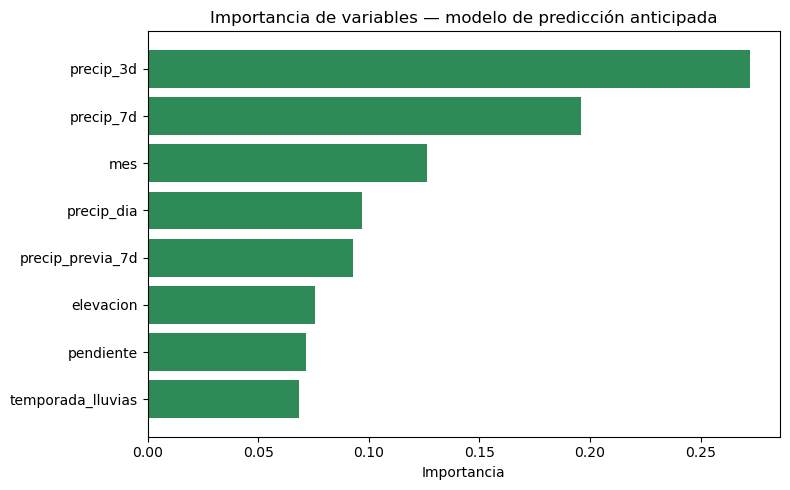

In [7]:
import matplotlib.pyplot as plt

importancias = pd.DataFrame({
    "variable": features,
    "importancia": modelo.feature_importances_,
}).sort_values("importancia", ascending=False)

print(importancias)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancias["variable"], importancias["importancia"], color="seagreen")
ax.set_xlabel("Importancia")
ax.set_title("Importancia de variables — modelo de predicción anticipada")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("../data/processed/importancia_variables_v2.png", dpi=150, bbox_inches="tight")
plt.show()

Recall 0.33: de cada 100 situaciones de riesgo reales, el modelo solo detecta 33. Se le escapan 2 de cada 3. Para un sistema de alerta, esto es insuficiente.
Precision 0.51: cuando avisa, acierta la mitad de las veces.
AUC 0.709: capacidad de discriminación moderada (0.5 sería azar, 0.7 es "flojo pero algo aprende").


En la matriz de confusión se ve claro: 88 falsos negativos (situaciones de riesgo que predijo como normales) frente a solo 44 aciertos. Un sistema de alerta que se pierde el 67% de los eventos no es aún utilizable.

# MEJORA 1: Bajar el umbral de decisión

Esta es la más rápida y la que más va a mejorar el recall. Te explico el concepto.

Cuando el modelo predice, internamente calcula una probabilidad de riesgo (0 a 1). Por defecto, clasifica como "riesgo" si esa probabilidad supera 0.5. Pero 0.5 es arbitrario.
En un sistema de alerta, un falso negativo (no avisar de una inundación real) es mucho más grave que un falso positivo (avisar de más). Así que nos interesa que el modelo sea más "miedoso": que dé la alarma con menos certeza. Eso se consigue bajando el umbral — por ejemplo, clasificar como riesgo si la probabilidad supera 0.25 en vez de 0.5.

Esto sube el recall (detecta más eventos reales) a costa de bajar algo la precisión (más falsas alarmas). Para una alerta temprana, ese intercambio merece la pena.

In [8]:
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix
import numpy as np

# Probamos distintos umbrales de decisión y vemos cómo cambian recall y precisión
print("=== Efecto del umbral de decisión ===")
print(f"{'Umbral':>8} {'Recall':>8} {'Precision':>10} {'Detectados':>12} {'Falsas alarmas':>16}")
for umbral in [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]:
    y_pred_u = (y_prob >= umbral).astype(int)
    cm = confusion_matrix(y_test, y_pred_u)
    vn, fp, fn, vp = cm.ravel()
    recall = vp / (vp + fn) if (vp + fn) > 0 else 0
    precision = vp / (vp + fp) if (vp + fp) > 0 else 0
    print(f"{umbral:>8.2f} {recall:>8.2f} {precision:>10.2f} "
          f"{vp:>5d}/{vp+fn:<5d} {fp:>10d}")

=== Efecto del umbral de decisión ===
  Umbral   Recall  Precision   Detectados   Falsas alarmas
    0.50     0.33       0.51    44/132           43
    0.40     0.39       0.41    51/132           73
    0.30     0.42       0.34    55/132          105
    0.25     0.43       0.30    57/132          131
    0.20     0.45       0.25    60/132          176
    0.15     0.46       0.21    61/132          227
    0.10     0.49       0.16    65/132          337


Esta celda no cambia el modelo, solo te enseña una tabla: para cada umbral posible, cuánto recall y precisión tendrías. Así eliges el punto de equilibrio con criterio, no a ciegas.

Vale, esta tabla nos dice algo importante, y no es buena noticia: bajar el umbral apenas mejora el recall. Te lo interpreto con honestidad.
Lectura de la tabla
Mira los extremos:

Umbral 0.50 → detecta 44 de 132 (recall 0.33)
Umbral 0.10 → detecta 65 de 132 (recall 0.49), pero con 337 falsas alarmas

Para pasar de detectar 44 eventos a detectar 65, el sistema tendría que dar 337 alarmas falsas. Y aun así se le escaparían 67 eventos reales (la mitad). El recall se queda estancado en torno a 0.45-0.49 por mucho que bajemos el umbral.
Qué significa esto: el problema no es dónde ponemos el corte. El problema es que el modelo no tiene suficiente señal para distinguir los casos. Las probabilidades que asigna a los eventos de riesgo y a los normales se solapan demasiado. Mover el umbral solo reorganiza el desastre, no lo arregla.
Esto encaja con lo que hablamos: el modelo intenta adivinar la lluvia de mañana sin información atmosférica. Le falta materia prima.

Conclusión: el umbral no basta, vamos a la Mejora 2
La Mejora 1 (umbral) ha resultado tener poco recorrido, y eso también es un resultado — lo documentas: "el ajuste del umbral de decisión no mejoró sustancialmente la capacidad de detección, lo que indicaba que la limitación residía en la capacidad discriminativa del modelo y no en el punto de operación".
Vamos a la Mejora 2: features nuevas. Aquí sí podemos darle al modelo información que ahora no tiene.

# MEJORA 2: Features de dinámica temporal

Ahora mismo el modelo ve la lluvia acumulada, pero no ve cómo evoluciona. Le vamos a añadir variables que capturan la tendencia:

precip_tendencia: ¿la lluvia va a más o a menos? (lluvia de hoy menos la de ayer). Un episodio que se intensifica es más peligroso.
dias_consecutivos_lluvia: cuántos días seguidos lleva lloviendo. Cuanto más largo el episodio, más saturado el suelo.
ratio_reciente: cuánto pesa la lluvia de hoy sobre el acumulado de 7 días. Distingue "chaparrón puntual" de "lluvia sostenida".
precip_max_3d: el día más lluvioso de los últimos 3. Capta los picos.

#### modificaciones en 07

In [10]:
import pandas as pd
import numpy as np

# Cargamos el dataset CON las features de dinámica
dataset = pd.read_parquet("../data/processed/features_modelo_RECONSTRUCCION.parquet")
dataset["fecha"] = pd.to_datetime(dataset["fecha"])
dataset = dataset.sort_values(["descripcion", "fecha"]).reset_index(drop=True)

print(f"Filas: {len(dataset):,}")
print(f"Columnas: {len(dataset.columns)}")
print(f"Estaciones: {dataset['descripcion'].nunique()}")
dataset.head(3)

Filas: 19,747
Columnas: 17
Estaciones: 115


,descripcion,fecha,lat,lon,subcuenca,precip_dia,precip_3d,precip_7d,precip_previa_7d,elevacion,pendiente,mes,temporada_lluvias,precip_tendencia,ratio_reciente,precip_max_3d,dias_consecutivos_lluvia
0,Acequia Moncada El Puig,2020-01-19,39.605677,-0.314405,DEL BAJO TURIA,29.4,29.4,29.4,0.0,18.675497,0.600955,1,0,0.0,1.000000,29.4,1
1,Acequia Moncada El Puig,2020-01-20,39.605677,-0.314405,DEL BAJO TURIA,40.8,70.2,70.2,29.4,18.675497,0.600955,1,0,11.4,0.581197,40.8,2
2,Acequia Moncada El Puig,2020-01-21,39.605677,-0.314405,DEL BAJO TURIA,18.2,88.4,88.4,70.2,18.675497,0.600955,1,0,-22.6,0.205882,40.8,3


In [11]:
# Paso 1: definimos el "riesgo" de cada día (mismos umbrales que el enfoque anterior)
cond_intensa   = dataset["precip_dia"] >= 60
cond_acumulada = dataset["precip_3d"] >= 100
cond_saturado  = (dataset["precip_dia"] >= 40) & (dataset["precip_previa_7d"] >= 40)

dataset["riesgo_dia"] = (cond_intensa | cond_acumulada | cond_saturado).astype(int)

# Paso 2: para cada estación, miramos el riesgo y la fecha del SIGUIENTE registro
dataset["riesgo_manana"] = dataset.groupby("descripcion")["riesgo_dia"].shift(-1)
dataset["fecha_siguiente"] = dataset.groupby("descripcion")["fecha"].shift(-1)

# Paso 3: calculamos cuántos días hay hasta el siguiente registro
dataset["dias_hasta_siguiente"] = (
    dataset["fecha_siguiente"] - dataset["fecha"]
).dt.days

# Paso 4: solo son válidas las filas donde el siguiente registro está a <= 3 días
#         (predecir "el día siguiente" no tiene sentido si el dato está a 2 semanas)
dataset_valido = dataset[
    (dataset["dias_hasta_siguiente"].notna()) &
    (dataset["dias_hasta_siguiente"] <= 3)
].copy()

dataset_valido["riesgo_manana"] = dataset_valido["riesgo_manana"].astype(int)

print(f"Filas totales: {len(dataset):,}")
print(f"Filas válidas para predicción anticipada: {len(dataset_valido):,}")
print(f"  (se descartan las que no tienen un registro siguiente cercano)")
print()
print(f"Distribución de la etiqueta 'riesgo_manana':")
print(f"  Riesgo (1): {dataset_valido['riesgo_manana'].sum()} "
      f"({dataset_valido['riesgo_manana'].mean()*100:.1f}%)")
print(f"  Normal (0): {(dataset_valido['riesgo_manana']==0).sum()}")

Filas totales: 19,747
Filas válidas para predicción anticipada: 8,711
  (se descartan las que no tienen un registro siguiente cercano)

Distribución de la etiqueta 'riesgo_manana':
  Riesgo (1): 488 (5.6%)
  Normal (0): 8223


In [12]:
# Features: ahora incluimos las de dinámica temporal
features = [
    "precip_dia", "precip_3d", "precip_7d", "precip_previa_7d",
    "elevacion", "pendiente", "mes", "temporada_lluvias",
    # nuevas features de dinámica (Mejora 2)
    "precip_tendencia", "ratio_reciente", "precip_max_3d",
    "dias_consecutivos_lluvia",
]
target = "riesgo_manana"

train = dataset_valido[dataset_valido["fecha"].dt.year <= 2023]
test  = dataset_valido[dataset_valido["fecha"].dt.year == 2024]

X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print(f"Entrenamiento: {len(X_train):,} filas — {y_train.sum()} de riesgo ({y_train.mean()*100:.1f}%)")
print(f"Test (2024):   {len(X_test):,} filas — {y_test.sum()} de riesgo ({y_test.mean()*100:.1f}%)")

Entrenamiento: 6,143 filas — 356 de riesgo (5.8%)
Test (2024):   2,568 filas — 132 de riesgo (5.1%)


In [17]:
### parte de la mejora 3
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
import xgboost as xgb

# Peso para el desbalanceo (igual que antes)
peso = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

# Espacio de búsqueda: rangos de valores a explorar para cada hiperparámetro
espacio = {
    "n_estimators":     [100, 200, 300, 400, 500],
    "max_depth":        [3, 4, 5, 6, 7],
    "learning_rate":    [0.01, 0.03, 0.05, 0.1],
    "subsample":        [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma":            [0, 0.1, 0.3, 0.5],
}

# Modelo base
modelo_base = xgb.XGBClassifier(
    scale_pos_weight=peso,
    eval_metric="aucpr",
    random_state=42,
)

# Validación cruzada respetando el orden temporal
# (TimeSeriesSplit no mezcla pasado y futuro dentro de la búsqueda)
cv_temporal = TimeSeriesSplit(n_splits=4)

# Búsqueda aleatoria: prueba 40 combinaciones
busqueda = RandomizedSearchCV(
    estimator=modelo_base,
    param_distributions=espacio,
    n_iter=40,                    # nº de combinaciones a probar
    scoring="roc_auc",            # métrica a optimizar
    cv=cv_temporal,
    random_state=42,
    n_jobs=-1,                    # usa todos los núcleos del procesador
    verbose=1,
)

print("Buscando la mejor combinación de hiperparámetros...")
print("(esto puede tardar 2-5 minutos)\n")

busqueda.fit(X_train, y_train)

print("\n=== Mejor combinación encontrada ===")
for param, valor in busqueda.best_params_.items():
    print(f"  {param}: {valor}")
print(f"\nAUC media en validación cruzada: {busqueda.best_score_:.3f}")

Buscando la mejor combinación de hiperparámetros...
(esto puede tardar 2-5 minutos)

Fitting 4 folds for each of 40 candidates, totalling 160 fits

=== Mejor combinación encontrada ===
  subsample: 0.8
  n_estimators: 300
  min_child_weight: 1
  max_depth: 5
  learning_rate: 0.03
  gamma: 0
  colsample_bytree: 1.0

AUC media en validación cruzada: 0.912


In [13]:
import xgboost as xgb

# Peso para compensar el desbalanceo de clases
peso = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
print(f"Ratio de desbalanceo (scale_pos_weight): {peso:.1f}")

modelo = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=peso,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="aucpr",
    random_state=42,
)

modelo.fit(X_train, y_train)
print("\nModelo entrenado.")

Ratio de desbalanceo (scale_pos_weight): 16.3

Modelo entrenado.


In [14]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print("=== Informe de clasificación (test 2024) ===")
print(classification_report(y_test, y_pred, target_names=["Normal", "Riesgo"]))

print("=== Matriz de confusión ===")
cm = confusion_matrix(y_test, y_pred)
print(f"                  Predicho")
print(f"                Normal  Riesgo")
print(f"Real Normal      {cm[0,0]:5d}   {cm[0,1]:5d}")
print(f"Real Riesgo      {cm[1,0]:5d}   {cm[1,1]:5d}")

print(f"\nAUC-ROC: {roc_auc_score(y_test, y_prob):.3f}")

=== Informe de clasificación (test 2024) ===
              precision    recall  f1-score   support

      Normal       0.97      0.99      0.98      2436
      Riesgo       0.63      0.39      0.48       132

    accuracy                           0.96      2568
   macro avg       0.80      0.69      0.73      2568
weighted avg       0.95      0.96      0.95      2568

=== Matriz de confusión ===
                  Predicho
                Normal  Riesgo
Real Normal       2406      30
Real Riesgo         81      51

AUC-ROC: 0.721


                    variable  importancia
10             precip_max_3d     0.273147
2                  precip_7d     0.138352
1                  precip_3d     0.081154
6                        mes     0.074487
0                 precip_dia     0.073522
7          temporada_lluvias     0.063201
11  dias_consecutivos_lluvia     0.056038
3           precip_previa_7d     0.055168
8           precip_tendencia     0.051543
4                  elevacion     0.048381
5                  pendiente     0.044878
9             ratio_reciente     0.040128


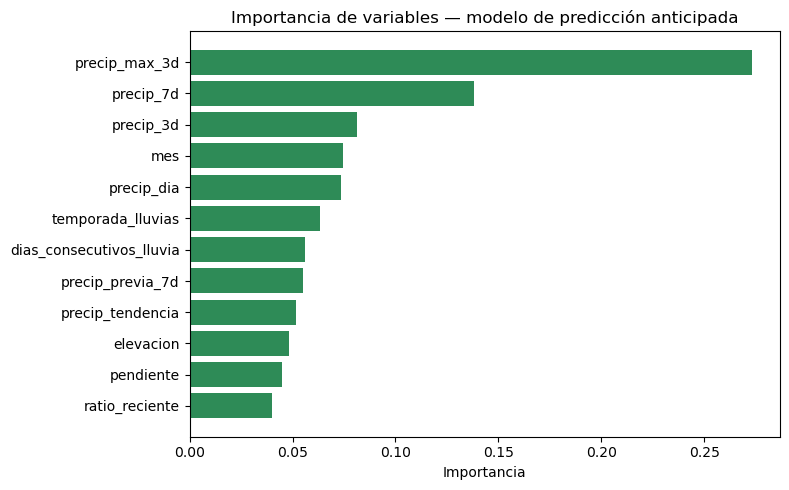

In [15]:
import matplotlib.pyplot as plt

importancias = pd.DataFrame({
    "variable": features,
    "importancia": modelo.feature_importances_,
}).sort_values("importancia", ascending=False)

print(importancias)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancias["variable"], importancias["importancia"], color="seagreen")
ax.set_xlabel("Importancia")
ax.set_title("Importancia de variables — modelo de predicción anticipada")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("../data/processed/importancia_variables_v2.png", dpi=150, bbox_inches="tight")
plt.show()

La Mejora 2 ha servido, sobre todo en precisión: ahora cuando el modelo avisa, acierta el 63% de las veces (antes 51%). Y detecta 51 eventos en vez de 44. No es espectacular, pero es una mejora medible y la documentas como tal.

Lo más interesante: la importancia de variables
Mira la nueva lista:

precip_max_3d se ha colado en el primer puesto (0.27). La feature nueva del pico de lluvia es la más predictiva de todas. Esto valida la Mejora 2: le diste al modelo una variable que no tenía y resultó ser la más útil.

La importancia ahora está mucho más repartida. Antes precip_7d solo se llevaba el 60%; ahora ninguna variable pasa del 27%. El modelo usa muchas señales combinadas, que es señal de un modelo más equilibrado.

Elevación y pendiente siguen abajo (0.048 y 0.045) pero ya no son cero — aportan un 9% conjunto. La topografía cuenta, modestamente.

La parte honesta: seguimos con un modelo limitado

No te voy a maquillar el resultado: recall 0.39 sigue siendo bajo para un sistema de alerta. Se siguen escapando 81 de 132 eventos (el 61%). El AUC 0.72 es "moderado".

Hemos exprimido casi todo lo que se puede sacar de los datos del SAIH solos. Las dos mejoras restantes que quedan:

Mejora 3 (hiperparámetros): ajustar la configuración de XGBoost. Honestamente, esto suele dar mejoras pequeñas (puede que +0.01-0.02 de AUC). No va a transformar el modelo.

Mejora 4 (variables de AEMET): añadir temperatura, presión, viento. Esto es lo único que podría dar un salto real, porque le daría al modelo la información atmosférica que ahora le falta. Pero implica trabajo: volver al feature engineering y cruzar AEMET con el dataset.

# MEJORA 3: Modificación de hiperparámetros

Qué son los hiperparámetros (para que lo expliques en la memoria)
Un modelo XGBoost tiene dos tipos de "ajustes":

Los parámetros los aprende solo durante el entrenamiento (las reglas de los árboles).
Los hiperparámetros los fijas tú antes de entrenar: cuántos árboles, cómo de profundos, a qué velocidad aprende, etc.

Cómo lo vamos a hacer: búsqueda con validación cruzada
Usaremos RandomizedSearchCV de scikit-learn. Te explico la idea sin tecnicismos:

Defines un rango de valores posibles para cada hiperparámetro.
La herramienta prueba muchas combinaciones al azar.
Cada combinación se evalúa con validación cruzada: divide el entrenamiento en trozos, entrena en unos y valida en otro, varias veces. Así la elección no depende de la suerte de una única división.
Te devuelve la mejor combinación encontrada.


Una cosa importante: la validación cruzada la haremos solo sobre los datos de entrenamiento (2020-2023). El test de 2024 sigue intacto, sin tocar, para la evaluación final. Esto es metodológicamente correcto: el test no debe influir en la elección de hiperparámetros.

ARRIBA CELDA CON ESTUDIO DE HIPERPARÁMETROS

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# El mejor modelo encontrado
modelo_optimizado = busqueda.best_estimator_

# Lo evaluamos sobre el test 2024 (que no se ha tocado durante la búsqueda)
y_pred = modelo_optimizado.predict(X_test)
y_prob = modelo_optimizado.predict_proba(X_test)[:, 1]

print("=== Informe de clasificación — modelo optimizado (test 2024) ===")
print(classification_report(y_test, y_pred, target_names=["Normal", "Riesgo"]))

print("=== Matriz de confusión ===")
cm = confusion_matrix(y_test, y_pred)
print(f"                  Predicho")
print(f"                Normal  Riesgo")
print(f"Real Normal      {cm[0,0]:5d}   {cm[0,1]:5d}")
print(f"Real Riesgo      {cm[1,0]:5d}   {cm[1,1]:5d}")

print(f"\nAUC-ROC: {roc_auc_score(y_test, y_prob):.3f}")

=== Informe de clasificación — modelo optimizado (test 2024) ===
              precision    recall  f1-score   support

      Normal       0.97      0.98      0.98      2436
      Riesgo       0.59      0.40      0.48       132

    accuracy                           0.95      2568
   macro avg       0.78      0.69      0.73      2568
weighted avg       0.95      0.95      0.95      2568

=== Matriz de confusión ===
                  Predicho
                Normal  Riesgo
Real Normal       2399      37
Real Riesgo         79      53

AUC-ROC: 0.717


                    variable  importancia
10             precip_max_3d     0.301856
2                  precip_7d     0.138523
1                  precip_3d     0.074776
7          temporada_lluvias     0.068013
6                        mes     0.066347
0                 precip_dia     0.063189
3           precip_previa_7d     0.054500
11  dias_consecutivos_lluvia     0.050041
8           precip_tendencia     0.048321
9             ratio_reciente     0.046935
4                  elevacion     0.045625
5                  pendiente     0.041875


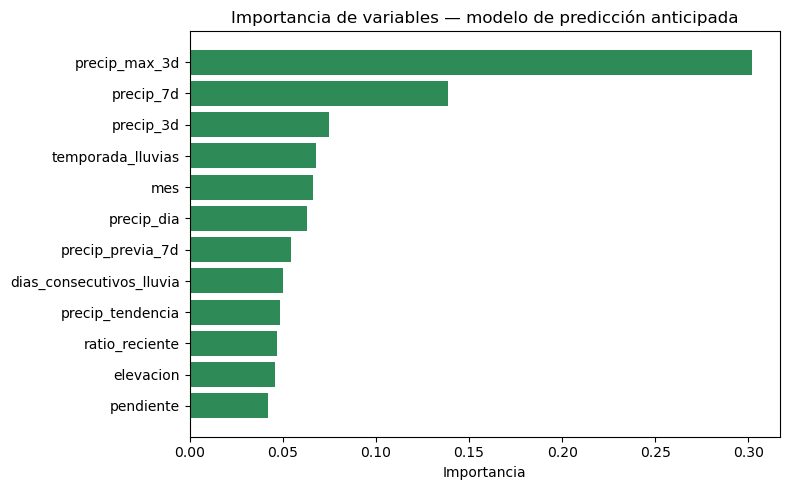

In [19]:
import matplotlib.pyplot as plt

importancias = pd.DataFrame({
    "variable": features,
    "importancia": modelo_optimizado.feature_importances_,
}).sort_values("importancia", ascending=False)

print(importancias)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancias["variable"], importancias["importancia"], color="seagreen")
ax.set_xlabel("Importancia")
ax.set_title("Importancia de variables — modelo de predicción anticipada")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("../data/processed/importancia_variables_v2_optimizado.png", dpi=150, bbox_inches="tight")
plt.show()

La diferencia es mínima, pero el primero:

tiene mejor AUC,
mejor precisión en la clase “Riesgo”,
menos falsos positivos,
y ligeramente mejor accuracy global.

El segundo modelo solo mejora muy ligeramente el recall (detecta 2 casos de riesgo más: 53 frente a 51), pero a costa de generar más falsos positivos.

La decisión final depende de qué te importe más:

Si prefieres detectar el máximo número posible de casos de riesgo, aunque haya más falsas alarmas → Modelo 2.
Si prefieres un modelo más equilibrado y “fiable” en sus alertas → Modelo 1.

Para un contexto real de negocio normalmente elegiría el segundo, salvo que perder un caso de riesgo tenga un coste muy alto.

In [ ]:
### decidir que modelo me quedo

import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)
joblib.dump(modelo_optimizado, "../models/modelo_riesgo_inundacion.pkl")
print("Modelo guardado en models/modelo_riesgo_inundacion.pkl")